Enquanto o Caderno 03 explorou os metadados dos participantes (idade, sexo, site e diagnóstico), este notebook realiza uma análise exploratória dos dados de conectividade funcional já calculados.

O objetivo é produzir visualizações didáticas que permitam observar, de forma preliminar, a distribuição dos participantes no espaço de conectividade e as diferenças médias entre os grupos TEA e Controle.

As visualizações produzidas neste notebook possuem finalidade exclusivamente exploratória e didática. Elas não constituem etapas da metodologia experimental de classificação e não são utilizadas diretamente como entrada dos modelos de Machine Learning.

Também é realizada uma visualização por site para observar possíveis padrões de agrupamento relacionados ao local de aquisição dos dados.

**Objetivo:** Realizar uma análise exploratória e didática dos dados de conectividade funcional, utilizando PCA, médias de conectividade por grupo e diferença entre os grupos TEA e Controle.

**Entradas:** `Data/conectivity/connectivity_matrices_abide_validado.pkl` (Caderno 05) e `Data/raw/phenotypic_abide.csv`.

**Processamento:** PCA com 2 componentes para visualização exploratória, cálculo da matriz média do grupo TEA, cálculo da matriz média do grupo Controle e cálculo da diferença entre as médias.

**Saídas:** Figuras exploratórias em `Figures/06_*.png` e resultados da análise em `Results/06_analise_exploratoria_conectividade.pkl`.

**Observação:** As visualizações e o PCA deste notebook possuem finalidade exclusivamente exploratória e didática. O espaço reduzido pelo PCA não é utilizado como entrada dos modelos de classificação.

In [1]:
# ------------------------------------------------------------
# Configuração do projeto (execução local — VS Code)
# Garante que a raiz do projeto esteja no sys.path, funcionando tanto se o
# diretório de trabalho do kernel for notebooks/ quanto a raiz do projeto.
# ------------------------------------------------------------
import sys
from pathlib import Path

_raiz = Path.cwd().resolve()
for _cand in (_raiz, *_raiz.parents):
    if (_cand / 'src' / 'config.py').exists():
        _raiz = _cand
        break
else:
    raise RuntimeError(
        'Não foi possível localizar a pasta src/config.py a partir de '
        f'{Path.cwd()}. Abra a pasta TCC_TEA_TDAH/ no VS Code.'
    )
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))

import os
import random
import numpy as np

from src.config import BASE_DIR, PATHS, SEED, criar_pastas
from src.utils import exigir_arquivo

criar_pastas()

random.seed(SEED)
np.random.seed(SEED)

print('Projeto (BASE_DIR) =', BASE_DIR)

Projeto (BASE_DIR) = C:\Users\Maria Eduarda\Downloads\TCC_TEA_TDAH


In [2]:
# ============================================================
# CARREGAMENTO DOS DADOS PARA ANÁLISE EXPLORATÓRIA
# ============================================================
exigir_arquivo(
    PATHS['conectivity']
    / 'connectivity_matrices_abide_validado.pkl',
    '05_Validacao_ABIDE.ipynb'
)

exigir_arquivo(
    PATHS['raw']
    / 'phenotypic_abide.csv',
    '02_Download_ABIDE.ipynb'
)

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from nilearn.connectome import sym_matrix_to_vec

# ------------------------------------------------------------
# Carregar matrizes de conectividade validadas
# ------------------------------------------------------------
conn_path = (
    PATHS['conectivity']
    / 'connectivity_matrices_abide_validado.pkl'
)

with open(conn_path, 'rb') as f:
    conn_dict = pickle.load(f)

conn_dict = {
    str(sub_id): np.asarray(mat)
    for sub_id, mat in conn_dict.items()
}

# ------------------------------------------------------------
# Carregar dados fenotípicos
# ------------------------------------------------------------
phenotypic = pd.read_csv(
    PATHS['raw'] / 'phenotypic_abide.csv'
)

phenotypic['SUB_ID'] = phenotypic['SUB_ID'].astype(str)
phenotypic = phenotypic.set_index('SUB_ID')

# ------------------------------------------------------------
# Garantir correspondência entre os participantes
# ------------------------------------------------------------
sub_ids = list(conn_dict.keys())

ids_sem_fenotipo = [
    sub_id
    for sub_id in sub_ids
    if sub_id not in phenotypic.index
]

if ids_sem_fenotipo:
    raise ValueError(
        'Existem participantes com matriz de conectividade '
        'sem correspondente nos dados fenotípicos. '
        f'Quantidade: {len(ids_sem_fenotipo)}'
    )

# ------------------------------------------------------------
# Organizar matrizes
# ------------------------------------------------------------
matrices = np.stack(
    [conn_dict[sub_id] for sub_id in sub_ids]
)

# ------------------------------------------------------------
# Vetorização somente para a visualização exploratória por PCA.
# Esta não é a etapa de extração final das características do TCC.
# ------------------------------------------------------------
vetores_exploratorios = sym_matrix_to_vec(
    matrices,
    discard_diagonal=True
)

# ------------------------------------------------------------
# Diagnóstico
# 1 = TEA
# 2 = Controle
# ------------------------------------------------------------
labels = phenotypic.loc[
    sub_ids,
    'DX_GROUP'
].to_numpy()

sites = phenotypic.loc[
    sub_ids,
    'SITE_ID'
].to_numpy()

print('Matrizes de conectividade:', matrices.shape)
print(
    'Vetores utilizados somente na análise exploratória:',
    vetores_exploratorios.shape
)
print('Participantes:', len(sub_ids))
print('Sites únicos:', len(np.unique(sites)))

Matrizes de conectividade: (871, 200, 200)
Vetores utilizados somente na análise exploratória: (871, 19900)
Participantes: 871
Sites únicos: 20


## PCA para visualização exploratória e didática

O PCA é utilizado exclusivamente para representar visualmente os participantes em um espaço bidimensional.

As 19.900 conexões são reduzidas a dois componentes apenas para fins de visualização. Essa representação não é utilizada como entrada dos modelos de classificação.

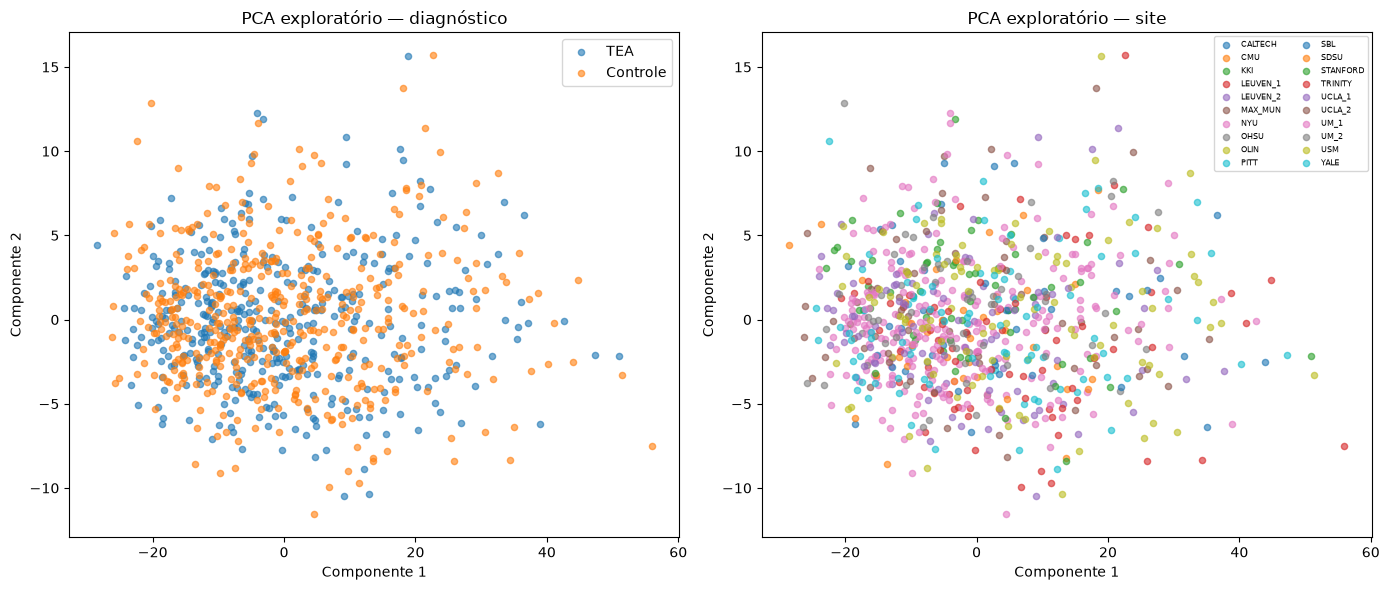

Variância explicada pelos 2 componentes: 31.38%

Observação: esta figura possui finalidade exclusivamente exploratória e didática.


In [3]:
# ============================================================
# PCA — VISUALIZAÇÃO EXPLORATÓRIA E DIDÁTICA
# ============================================================
pca = PCA(
    n_components=2,
    random_state=SEED
)

proj = pca.fit_transform(
    vetores_exploratorios
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)

# ------------------------------------------------------------
# Visualização por diagnóstico
# ------------------------------------------------------------
for label, nome in [
    (1, 'TEA'),
    (2, 'Controle')
]:
    mask = labels == label

    axes[0].scatter(
        proj[mask, 0],
        proj[mask, 1],
        label=nome,
        alpha=0.6,
        s=20
    )

axes[0].set_title(
    'PCA exploratório — diagnóstico'
)
axes[0].set_xlabel('Componente 1')
axes[0].set_ylabel('Componente 2')
axes[0].legend()

# ------------------------------------------------------------
# Visualização por site
# ------------------------------------------------------------
sites_unicos = np.unique(sites)

for site in sites_unicos:
    mask = sites == site

    axes[1].scatter(
        proj[mask, 0],
        proj[mask, 1],
        label=site,
        alpha=0.6,
        s=20
    )

axes[1].set_title(
    'PCA exploratório — site'
)
axes[1].set_xlabel('Componente 1')
axes[1].set_ylabel('Componente 2')
axes[1].legend(
    fontsize=6,
    ncol=2
)

plt.tight_layout()

fig_path = (
    PATHS['figures']
    / '06_pca_diagnostico_vs_site.png'
)

plt.savefig(
    fig_path,
    dpi=150,
    bbox_inches='tight'
)

plt.show()

variancia_explicada = (
    pca.explained_variance_ratio_.sum()
)

print(
    'Variância explicada pelos 2 componentes:',
    f'{variancia_explicada:.2%}'
)

print()
print(
    'Observação: esta figura possui finalidade '
    'exclusivamente exploratória e didática.'
)

## Matrizes de conectividade média — análise exploratória e didática

As matrizes abaixo representam a conectividade média dos grupos TEA e Controle e a diferença entre essas médias.

Essas imagens têm finalidade exclusivamente exploratória e didática. Elas não representam uma etapa de treinamento dos modelos e não são utilizadas diretamente como entrada do Machine Learning.

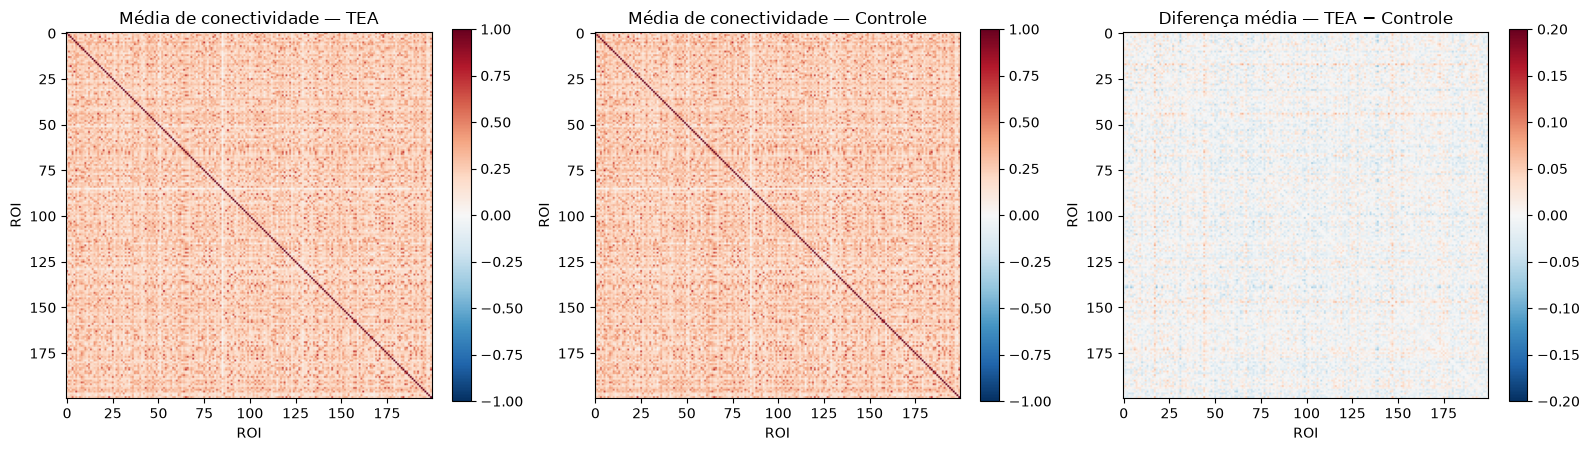

Figura de conectividade média por grupo salva em: C:\Users\Maria Eduarda\Downloads\TCC_TEA_TDAH\Figures\06_conectividade_media_por_grupo.png
Observação: as matrizes exibidas possuem finalidade exclusivamente exploratória e didática.


In [4]:
# ============================================================
# MATRIZES MÉDIAS POR GRUPO
# ANÁLISE EXPLORATÓRIA E DIDÁTICA
# ============================================================

media_tea = matrices[
    labels == 1
].mean(axis=0)

media_controle = matrices[
    labels == 2
].mean(axis=0)

diferenca = (
    media_tea
    - media_controle
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

matrizes_plot = [
    media_tea,
    media_controle,
    diferenca
]

titulos = [
    'Média de conectividade — TEA',
    'Média de conectividade — Controle',
    'Diferença média — TEA − Controle'
]

for ax, mat, titulo in zip(
    axes,
    matrizes_plot,
    titulos
):
    if 'Diferença' in titulo:
        vmin = -0.2
        vmax = 0.2
    else:
        vmin = -1
        vmax = 1

    im = ax.imshow(
        mat,
        cmap='RdBu_r',
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(titulo)
    ax.set_xlabel('ROI')
    ax.set_ylabel('ROI')

    plt.colorbar(
        im,
        ax=ax,
        fraction=0.046
    )

plt.tight_layout()

fig_path = (
    PATHS['figures']
    / '06_conectividade_media_por_grupo.png'
)

plt.savefig(
    fig_path,
    dpi=150,
    bbox_inches='tight'
)

plt.show()

print(
    'Figura de conectividade média por grupo salva em:',
    fig_path
)

print(
    'Observação: as matrizes exibidas possuem finalidade '
    'exclusivamente exploratória e didática.'
)

In [5]:
# ============================================================
# SALVAR RESULTADOS DA ANÁLISE EXPLORATÓRIA
# ============================================================

resultado_06 = {
    'media_tea': media_tea,
    'media_controle': media_controle,
    'diferenca': diferenca,
    'pca_variancia_explicada': pca.explained_variance_ratio_,
}

resultado_path = (
    PATHS['results']
    / '06_analise_exploratoria_conectividade.pkl'
)

with open(
    resultado_path,
    'wb'
) as f:
    pickle.dump(
        resultado_06,
        f
    )

print(
    'Resultados da análise exploratória salvos em:',
    resultado_path
)

print(
    'Observação: esses resultados são destinados à '
    'análise exploratória/didática e não constituem '
    'o dataset final utilizado no treinamento dos modelos.'
)

Resultados da análise exploratória salvos em: C:\Users\Maria Eduarda\Downloads\TCC_TEA_TDAH\Results\06_analise_exploratoria_conectividade.pkl
Observação: esses resultados são destinados à análise exploratória/didática e não constituem o dataset final utilizado no treinamento dos modelos.
